In [22]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import Sam2Model, Sam2Processor

In [23]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

CHECKPOINT_PATH = (
    "sam2_vegann_checkpoints/"
    "best_sam2_vegann_mask_decoder.pt"
)

EXG_PERCENTILE = 60
BOX_PADDING = 0
NUM_POSITIVE_POINTS = 3

MASK_THRESHOLD = 0.5

print("Device:", device)
print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))

Device: cuda
Checkpoint exists: True


In [24]:
#Loading VegANN 
dataset = load_dataset("simonMadec/VegAnn")

print(dataset)
print(dataset["train"].column_names)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=512x512 at 0x756628724280>, 'mask': <PIL.PngImagePlugin.PngImageFile image mode=L size=512x512 at 0x756628726050>, 'System': 'Handeld Cameras', 'Orientation': 'Nadir', 'latitude': 43.916686, 'longitude': 4.879169, 'date': '2019-06', 'LocAcc': 1, 'Species': 'Mix', 'Owner': 'Arvalis', 'Dataset-Name': 'Literal', 'TVT-split1': 'Test', 'TVT-split2': 'Training', 'TVT-split3': 'Training', 'TVT-split4': 'Training', 'TVT-split5': 'Training'}


In [25]:
#80/20 train/val split 
full_dataset = dataset["train"]

split_dataset = full_dataset.train_test_split(
    test_size=0.20,
    seed=SEED,
    shuffle=True
)

train_split = split_dataset["train"]
val_split = split_dataset["test"]

print("Full dataset:", len(full_dataset))
print("Training split:", len(train_split))
print("Validation split:", len(val_split))

Full dataset: 3775
Training split: 3020
Validation split: 755


In [26]:
#identifying image and mask cols
print("Columns:", val_split.column_names)

possible_image_columns = [
    "image",
    "img",
    "rgb",
]

possible_mask_columns = [
    "mask",
    "label",
    "segmentation_mask",
    "annotation",
]

IMAGE_COLUMN = next(
    col for col in possible_image_columns
    if col in val_split.column_names
)

MASK_COLUMN = next(
    col for col in possible_mask_columns
    if col in val_split.column_names
)

print("Image column:", IMAGE_COLUMN)
print("Mask column:", MASK_COLUMN)

Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Image column: image
Mask column: mask


In [27]:
#Image and mask conversion 
def prepare_rgb_image(image):
    """
    Convert a dataset image to an RGB PIL image.
    """
    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.asarray(image))

    return image.convert("RGB")


def prepare_binary_mask(mask):
    """
    Convert a VegAnn mask into a binary uint8 array containing 0 and 1.
    """
    if isinstance(mask, Image.Image):
        mask = np.asarray(mask)
    else:
        mask = np.asarray(mask)

    # Handle masks with multiple channels.
    if mask.ndim == 3:
        mask = mask[..., 0]

    binary_mask = (mask > 0).astype(np.uint8)

    return binary_mask

In [28]:
#Auto vegetation box 
def get_vegetation_box_from_image_full(
    image,
    padding=0,
    percentile=60
):
    """
    Generate an automatic vegetation box using the same method
    used in the pretrained SAM2 ablation study.

    Parameters
    ----------
    image:
        RGB NumPy array with shape [H, W, 3] and values in [0, 255].
    padding:
        Number of pixels added around the detected box.
    percentile:
        Percentile used to calculate the image-specific ExG threshold.

    Returns
    -------
    box:
        NumPy array [x1, y1, x2, y2].
    veg_mask:
        Automatically estimated binary vegetation mask.
    """
    image = np.asarray(image)

    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError(
            f"Expected RGB image with shape [H, W, 3], "
            f"but received {image.shape}."
        )

    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = (2.0 * g) - r - b

    threshold = np.percentile(
        exg,
        percentile
    )

    # Keep this identical to the pretrained SAM2 experiment.
    veg_mask = exg < threshold

    ys, xs = np.where(veg_mask)

    height, width = image.shape[:2]

    if len(xs) == 0 or len(ys) == 0:
        fallback_box = np.array([
            width // 4,
            height // 4,
            3 * width // 4,
            3 * height // 4
        ])

        return fallback_box, veg_mask

    x1 = max(int(xs.min()) - padding, 0)
    y1 = max(int(ys.min()) - padding, 0)
    x2 = min(int(xs.max()) + padding, width - 1)
    y2 = min(int(ys.max()) + padding, height - 1)

    box = np.array(
        [x1, y1, x2, y2],
        dtype=np.int64
    )

    return box, veg_mask


In [29]:
#pOSITIVE points function 
def get_three_positive_points_from_estimated_mask(
    estimated_veg_mask
):
    """
    Generate the same three positive points used in the
    pretrained SAM2 ablation study.
    """
    ys, xs = np.where(estimated_veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        height, width = estimated_veg_mask.shape

        return np.array([
            [width // 2, height // 2],
            [width // 3, height // 3],
            [2 * width // 3, 2 * height // 3]
        ], dtype=np.int64)

    points = []

    # Centroid.
    points.append([
        int(xs.mean()),
        int(ys.mean())
    ])

    # First quartile-like point.
    q1 = len(xs) // 4

    points.append([
        int(xs[q1]),
        int(ys[q1])
    ])

    # Third quartile-like point.
    q3 = 3 * len(xs) // 4

    points.append([
        int(xs[q3]),
        int(ys[q3])
    ])

    return np.asarray(
        points,
        dtype=np.int64
    )

In [30]:
#Combined prompt generator 
def generate_auto_prompts(
    image,
    percentile=60,
    padding=0
):
    """
    Generate the same automatic box and three positive points
    used in the pretrained SAM2 experiment.

    Ground-truth masks are not used.
    """
    pil_image = prepare_rgb_image(image)
    image_array = np.asarray(pil_image)

    box, estimated_veg_mask = (
        get_vegetation_box_from_image_full(
            image=image_array,
            padding=padding,
            percentile=percentile
        )
    )

    positive_points = (
        get_three_positive_points_from_estimated_mask(
            estimated_veg_mask
        )
    )

    positive_labels = np.ones(
        len(positive_points),
        dtype=np.int64
    )

    return {
        "box": box.tolist(),
        "points": positive_points.tolist(),
        "point_labels": positive_labels.tolist(),
        "estimated_veg_mask": estimated_veg_mask.astype(
            np.uint8
        )
    }

In [31]:
#Testing prompt generation visually 
sample_index = 0

sample = val_split[sample_index]

sample_image = prepare_rgb_image(
    sample[IMAGE_COLUMN]
)

sample_gt_mask = prepare_binary_mask(
    sample[MASK_COLUMN]
)

sample_prompts = generate_auto_prompts(
    image=sample_image,
    percentile=EXG_PERCENTILE,
    padding=BOX_PADDING
)

print(sample_prompts)

{'box': [0, 0, 511, 511], 'points': [[306, 219], [374, 88], [507, 368]], 'point_labels': [1, 1, 1], 'estimated_veg_mask': array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], shape=(512, 512), dtype=uint8)}


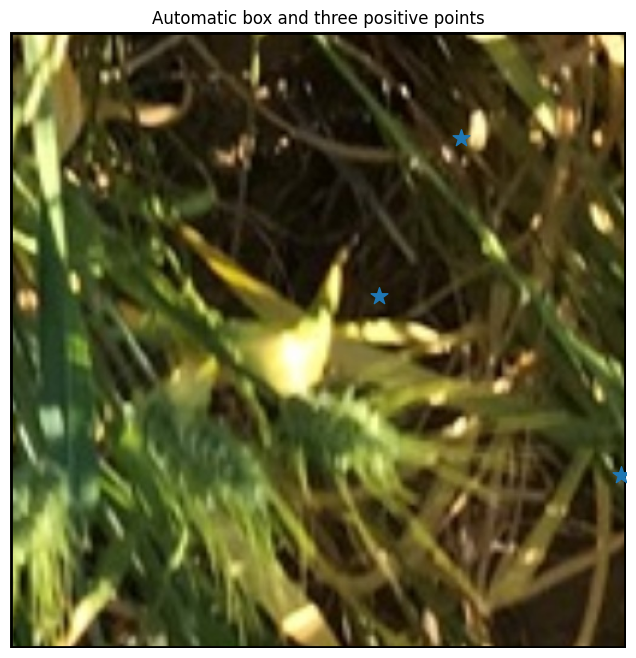

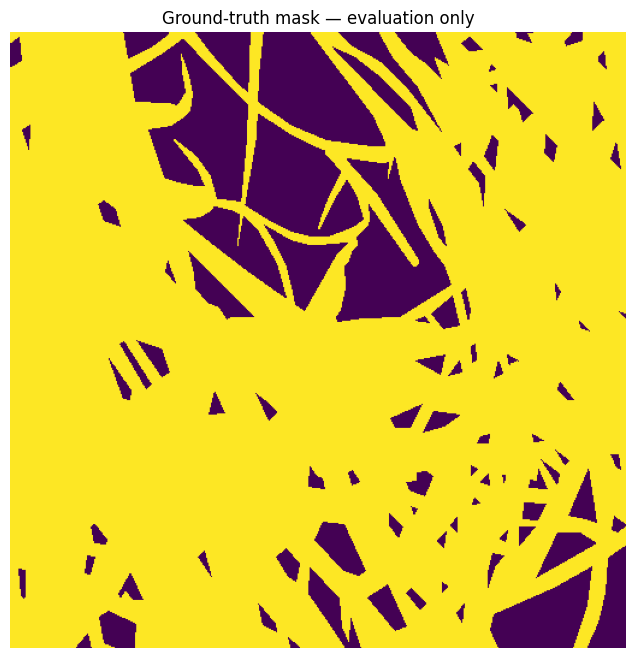

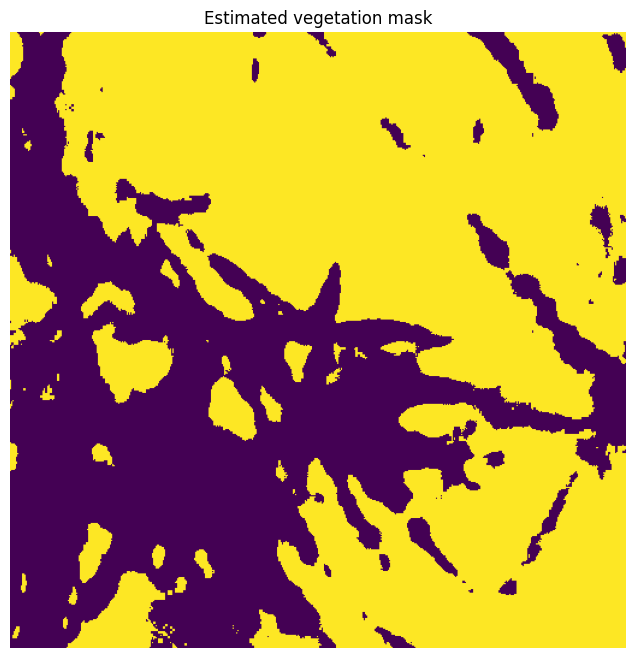

In [32]:
#Visualize AB and 3 points 
def visualize_prompts(
    image,
    ground_truth_mask,
    prompt_data
):
    image_array = np.asarray(image)

    plt.figure(figsize=(8, 8))
    plt.imshow(image_array)

    if prompt_data is not None:
        x_min, y_min, x_max, y_max = prompt_data["box"]

        rectangle = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        points = np.asarray(prompt_data["points"])

        plt.scatter(
            points[:, 0],
            points[:, 1],
            marker="*",
            s=160
        )

    plt.title("Automatic box and three positive points")
    plt.axis("off")
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.imshow(ground_truth_mask)
    plt.title("Ground-truth mask — evaluation only")
    plt.axis("off")
    plt.show()

    if prompt_data is not None:
        plt.figure(figsize=(8, 8))
        plt.imshow(prompt_data["estimated_veg_mask"])
        plt.title("Estimated vegetation mask")
        plt.axis("off")
        plt.show()


visualize_prompts(
    sample_image,
    sample_gt_mask,
    sample_prompts
)

In [33]:
#Loading processor and a fresh SAM2 model 
processor = Sam2Processor.from_pretrained(MODEL_NAME)

model = Sam2Model.from_pretrained(MODEL_NAME)

model = model.to(device)

print("Loaded:", MODEL_NAME)


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded: facebook/sam2.1-hiera-tiny


In [34]:
#Inspect saved checkpoint 
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

print("Checkpoint keys:")
print(checkpoint.keys())

print("Saved epoch:", checkpoint["epoch"])
print("Saved model:", checkpoint["model_name"])
print(
    "Best validation Mean IoU:",
    checkpoint["best_mean_iou"]
)

Checkpoint keys:
dict_keys(['epoch', 'model_name', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history'])
Saved epoch: 8
Saved model: facebook/sam2.1-hiera-tiny
Best validation Mean IoU: 0.8724805513351916


In [35]:
load_result = model.mask_decoder.load_state_dict(
    checkpoint["mask_decoder_state_dict"],
    strict=True
)

print("Mask decoder loaded successfully.")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

model = model.to(device)
model.eval()

Mask decoder loaded successfully.
Missing keys: []
Unexpected keys: []


Sam2Model(
  (shared_image_embedding): Sam2PositionalEmbedding()
  (vision_encoder): Sam2VisionModel(
    (backbone): Sam2HieraDetModel(
      (patch_embed): Sam2PatchEmbeddings(
        (projection): Conv2d(3, 96, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
      )
      (blocks): ModuleList(
        (0): Sam2MultiScaleBlock(
          (layer_norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (attn): Sam2MultiScaleAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (proj): Linear(in_features=96, out_features=96, bias=True)
          )
          (layer_norm2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (mlp): Sam2FeedForward(
            (activation): GELUActivation()
            (proj_in): Linear(in_features=96, out_features=384, bias=True)
            (proj_out): Linear(in_features=384, out_features=96, bias=True)
            (layers): ModuleList()
          )
        )
    

In [36]:
print(
    f"Checkpoint epoch: {checkpoint['epoch']}"
)

print(
    f"Checkpoint best Mean IoU: "
    f"{checkpoint['best_mean_iou'] * 100:.2f}%"
)

print(
    "Model is in evaluation mode:",
    not model.training
)

Checkpoint epoch: 8
Checkpoint best Mean IoU: 87.25%
Model is in evaluation mode: True


In [37]:
#Verifying that the checkpoint matches the trained decoder 
trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(
    f"Total loaded model parameters: "
    f"{trainable_parameter_count:,}"
)

print("Model evaluation mode:", not model.training)

Total loaded model parameters: 31,440,721
Model evaluation mode: True


In [38]:
#Prediction helper 
@torch.no_grad()
def predict_with_auto_prompts(
    model,
    processor,
    image,
    prompt_data,
    device
):
    """
    Predict a binary segmentation mask from one image using:
    - one automatic box;
    - three automatic positive points.
    """
    if prompt_data is None:
        return None, None

    input_boxes = [
        [prompt_data["box"]]
    ]

    input_points = [
        [prompt_data["points"]]
    ]

    input_labels = [
        [prompt_data["point_labels"]]
    ]

    inputs = processor(
        images=image,
        input_boxes=input_boxes,
        input_points=input_points,
        input_labels=input_labels,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        if isinstance(value, torch.Tensor)
        else value
        for key, value in inputs.items()
    }

    outputs = model(
        **inputs,
        multimask_output=False
    )

    # Typical SAM2 shape:
    # [batch, number_of_objects, number_of_masks, H, W]
    logits = outputs.pred_masks

    while logits.ndim > 2:
        logits = logits[0]

    # Restore prediction to original image resolution.
    original_height = image.height
    original_width = image.width

    logits = F.interpolate(
        logits.unsqueeze(0).unsqueeze(0),
        size=(original_height, original_width),
        mode="bilinear",
        align_corners=False
    ).squeeze(0).squeeze(0)

    probabilities = torch.sigmoid(logits)

    prediction = (
        probabilities >= MASK_THRESHOLD
    ).cpu().numpy().astype(np.uint8)

    return prediction, probabilities.cpu().numpy()

In [39]:
#Test one prediction 
prediction, probability_map = predict_with_auto_prompts(
    model=model,
    processor=processor,
    image=sample_image,
    prompt_data=sample_prompts,
    device=device
)

print("Prediction shape:", prediction.shape)
print("Ground truth shape:", sample_gt_mask.shape)
print("Unique prediction values:", np.unique(prediction))

Prediction shape: (512, 512)
Ground truth shape: (512, 512)
Unique prediction values: [0 1]


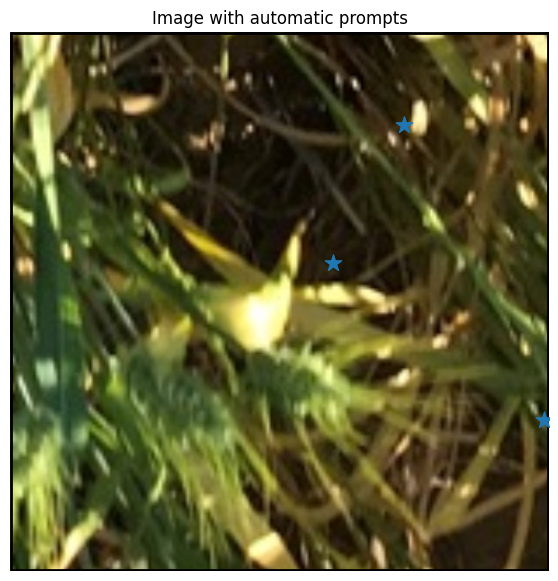

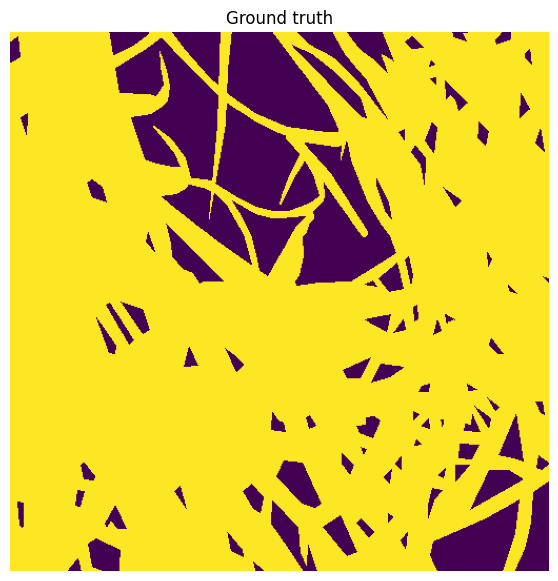

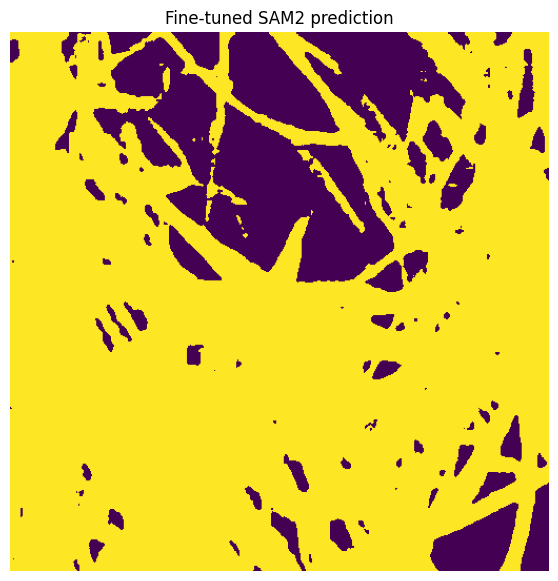

In [40]:
#Visualize one prediction 
def visualize_prediction(
    image,
    ground_truth_mask,
    predicted_mask,
    prompt_data
):
    plt.figure(figsize=(7, 7))
    plt.imshow(image)

    if prompt_data is not None:
        x_min, y_min, x_max, y_max = prompt_data["box"]

        rectangle = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        points = np.asarray(prompt_data["points"])

        plt.scatter(
            points[:, 0],
            points[:, 1],
            marker="*",
            s=150
        )

    plt.title("Image with automatic prompts")
    plt.axis("off")
    plt.show()

    plt.figure(figsize=(7, 7))
    plt.imshow(ground_truth_mask)
    plt.title("Ground truth")
    plt.axis("off")
    plt.show()

    plt.figure(figsize=(7, 7))
    plt.imshow(predicted_mask)
    plt.title("Fine-tuned SAM2 prediction")
    plt.axis("off")
    plt.show()


visualize_prediction(
    image=sample_image,
    ground_truth_mask=sample_gt_mask,
    predicted_mask=prediction,
    prompt_data=sample_prompts
)

In [41]:
#Metric function 
def calculate_binary_metrics(
    prediction,
    target,
    epsilon=1e-7
):
    prediction = (prediction > 0).astype(np.uint8)
    target = (target > 0).astype(np.uint8)

    intersection = np.logical_and(
        prediction,
        target
    ).sum()

    union = np.logical_or(
        prediction,
        target
    ).sum()

    prediction_sum = prediction.sum()
    target_sum = target.sum()

    if union == 0:
        iou = 1.0
    else:
        iou = intersection / (union + epsilon)

    denominator = prediction_sum + target_sum

    if denominator == 0:
        dice = 1.0
    else:
        dice = (
            2.0 * intersection /
            (denominator + epsilon)
        )

    true_positive = intersection
    false_positive = np.logical_and(
        prediction == 1,
        target == 0
    ).sum()

    false_negative = np.logical_and(
        prediction == 0,
        target == 1
    ).sum()

    return {
        "iou": float(iou),
        "dice": float(dice),
        "intersection": int(true_positive),
        "false_positive": int(false_positive),
        "false_negative": int(false_negative),
        "prediction_pixels": int(prediction_sum),
        "target_pixels": int(target_sum),
    }

In [42]:
#Evaluating only 10 images 
def evaluate_finetuned_sam2(
    model,
    processor,
    validation_dataset,
    image_column,
    mask_column,
    maximum_images=None
):
    model.eval()

    number_of_images = len(validation_dataset)

    if maximum_images is not None:
        number_of_images = min(
            maximum_images,
            number_of_images
        )

    records = []

    global_intersection = 0
    global_false_positive = 0
    global_false_negative = 0

    failed_prompt_count = 0

    for index in tqdm(range(number_of_images)):
        sample = validation_dataset[index]

        image = prepare_rgb_image(
            sample[image_column]
        )

        target = prepare_binary_mask(
            sample[mask_column]
        )

        prompt_data = generate_auto_prompts(
            image=image,
            percentile = EXG_PERCENTILE,
            padding=BOX_PADDING,
            
        )

        if prompt_data is None:
            failed_prompt_count += 1

            # Practical automatic-system behaviour:
            # no detected vegetation produces an empty prediction.
            prediction = np.zeros_like(
                target,
                dtype=np.uint8
            )

        else:
            prediction, _ = predict_with_auto_prompts(
                model=model,
                processor=processor,
                image=image,
                prompt_data=prompt_data,
                device=device
            )

        metrics = calculate_binary_metrics(
            prediction=prediction,
            target=target
        )

        global_intersection += metrics["intersection"]
        global_false_positive += metrics["false_positive"]
        global_false_negative += metrics["false_negative"]

        records.append({
            "index": index,
            "iou": metrics["iou"],
            "dice": metrics["dice"],
            "prompt_failed": prompt_data is None,
            "prediction_pixels": metrics["prediction_pixels"],
            "target_pixels": metrics["target_pixels"],
        })

    results_dataframe = pd.DataFrame(records)

    mean_iou = results_dataframe["iou"].mean()
    mean_dice = results_dataframe["dice"].mean()

    global_union = (
        global_intersection +
        global_false_positive +
        global_false_negative
    )

    global_iou = (
        global_intersection /
        (global_union + 1e-7)
    )

    global_dice = (
        2.0 * global_intersection /
        (
            2.0 * global_intersection +
            global_false_positive +
            global_false_negative +
            1e-7
        )
    )

    summary = {
        "images_evaluated": number_of_images,
        "prompt_failures": failed_prompt_count,
        "mean_iou": mean_iou,
        "mean_dice": mean_dice,
        "global_iou": global_iou,
        "global_dice": global_dice,
    }

    return summary, results_dataframe

In [43]:
small_summary, small_results = evaluate_finetuned_sam2(
    model=model,
    processor=processor,
    validation_dataset=val_split,
    image_column=IMAGE_COLUMN,
    mask_column=MASK_COLUMN,
    maximum_images=10
)

small_summary

  0%|          | 0/10 [00:00<?, ?it/s]

{'images_evaluated': 10,
 'prompt_failures': 0,
 'mean_iou': np.float64(0.8829253719388388),
 'mean_dice': np.float64(0.9361968176500428),
 'global_iou': 0.8921037685665154,
 'global_dice': 0.9429755210966954}

In [44]:
print("=" * 60)
print("SMALL TEST: FINE-TUNED SAM2")
print("Prompt: ExG60 + Pad0 + 3 positive points")
print("=" * 60)

print(
    f"Images evaluated: "
    f"{small_summary['images_evaluated']}"
)

print(
    f"Prompt failures: "
    f"{small_summary['prompt_failures']}"
)

print(
    f"Mean IoU: "
    f"{small_summary['mean_iou'] * 100:.2f}%"
)

print(
    f"Mean Dice: "
    f"{small_summary['mean_dice'] * 100:.2f}%"
)

print(
    f"Global IoU: "
    f"{small_summary['global_iou'] * 100:.2f}%"
)

print(
    f"Global Dice: "
    f"{small_summary['global_dice'] * 100:.2f}%"
)

SMALL TEST: FINE-TUNED SAM2
Prompt: ExG60 + Pad0 + 3 positive points
Images evaluated: 10
Prompt failures: 0
Mean IoU: 88.29%
Mean Dice: 93.62%
Global IoU: 89.21%
Global Dice: 94.30%


In [45]:
full_summary, full_results = evaluate_finetuned_sam2(
    model=model,
    processor=processor,
    validation_dataset=val_split,
    image_column=IMAGE_COLUMN,
    mask_column=MASK_COLUMN,
    maximum_images=None
)

  0%|          | 0/755 [00:00<?, ?it/s]

In [46]:
print("=" * 70)
print("FINE-TUNED SAM2 + AUTO BOX + 3 POSITIVE POINTS")
print("=" * 70)

print(
    f"Images evaluated: "
    f"{full_summary['images_evaluated']}"
)

print(
    f"Prompt failures: "
    f"{full_summary['prompt_failures']}"
)

print(
    f"Mean per-image IoU: "
    f"{full_summary['mean_iou'] * 100:.2f}%"
)

print(
    f"Mean per-image Dice: "
    f"{full_summary['mean_dice'] * 100:.2f}%"
)

print(
    f"Global IoU: "
    f"{full_summary['global_iou'] * 100:.2f}%"
)

print(
    f"Global Dice: "
    f"{full_summary['global_dice'] * 100:.2f}%"
)

FINE-TUNED SAM2 + AUTO BOX + 3 POSITIVE POINTS
Images evaluated: 755
Prompt failures: 0
Mean per-image IoU: 84.93%
Mean per-image Dice: 90.64%
Global IoU: 88.89%
Global Dice: 94.12%


In [47]:
OUTPUT_DIRECTORY = (
    "sam2_vegann_auto_prompt_evaluation"
)

os.makedirs(
    OUTPUT_DIRECTORY,
    exist_ok=True
)

full_results.to_csv(
    os.path.join(
        OUTPUT_DIRECTORY,
        "finetuned_sam2_auto_box_3points_per_image.csv"
    ),
    index=False
)

summary_dataframe = pd.DataFrame([
    {
        "model": "Fine-tuned SAM2.1 Hiera Tiny",
        "fine_tuning": "Mask decoder only",
        "dataset": "VegAnn validation",
        "prompt": "ExG60 + Pad0 + 3 positive points",
        "images": full_summary["images_evaluated"],
        "prompt_failures": full_summary["prompt_failures"],
        "mean_iou_percent": (
            full_summary["mean_iou"] * 100
        ),
        "mean_dice_percent": (
            full_summary["mean_dice"] * 100
        ),
        "global_iou_percent": (
            full_summary["global_iou"] * 100
        ),
        "global_dice_percent": (
            full_summary["global_dice"] * 100
        ),
    }
])

summary_dataframe.to_csv(
    os.path.join(
        OUTPUT_DIRECTORY,
        "finetuned_sam2_auto_box_3points_summary.csv"
    ),
    index=False
)

summary_dataframe

,model,fine_tuning,dataset,prompt,images,prompt_failures,mean_iou_percent,mean_dice_percent,global_iou_percent,global_dice_percent
0,Fine-tuned SAM2.1 Hiera Tiny,Mask decoder only,VegAnn validation,ExG60 + Pad0 + 3 positive points,755,0,84.925312,90.636449,88.887602,94.116926


In [48]:
OUTPUT_DIRECTORY = (
    "sam2_vegann_auto_prompt_evaluation"
)

os.makedirs(
    OUTPUT_DIRECTORY,
    exist_ok=True
)

full_results.to_csv(
    os.path.join(
        OUTPUT_DIRECTORY,
        "finetuned_sam2_auto_box_3points_per_image.csv"
    ),
    index=False
)

summary_dataframe = pd.DataFrame([
    {
        "model": "Fine-tuned SAM2.1 Hiera Tiny",
        "fine_tuning": "Mask decoder only",
        "dataset": "VegAnn validation",
        "prompt": "ExG60 + Pad0 + 3 positive points",
        "images": full_summary["images_evaluated"],
        "prompt_failures": full_summary["prompt_failures"],
        "mean_iou_percent": (
            full_summary["mean_iou"] * 100
        ),
        "mean_dice_percent": (
            full_summary["mean_dice"] * 100
        ),
        "global_iou_percent": (
            full_summary["global_iou"] * 100
        ),
        "global_dice_percent": (
            full_summary["global_dice"] * 100
        ),
    }
])

summary_dataframe.to_csv(
    os.path.join(
        OUTPUT_DIRECTORY,
        "finetuned_sam2_auto_box_3points_summary.csv"
    ),
    index=False
)

summary_dataframe

,model,fine_tuning,dataset,prompt,images,prompt_failures,mean_iou_percent,mean_dice_percent,global_iou_percent,global_dice_percent
0,Fine-tuned SAM2.1 Hiera Tiny,Mask decoder only,VegAnn validation,ExG60 + Pad0 + 3 positive points,755,0,84.925312,90.636449,88.887602,94.116926


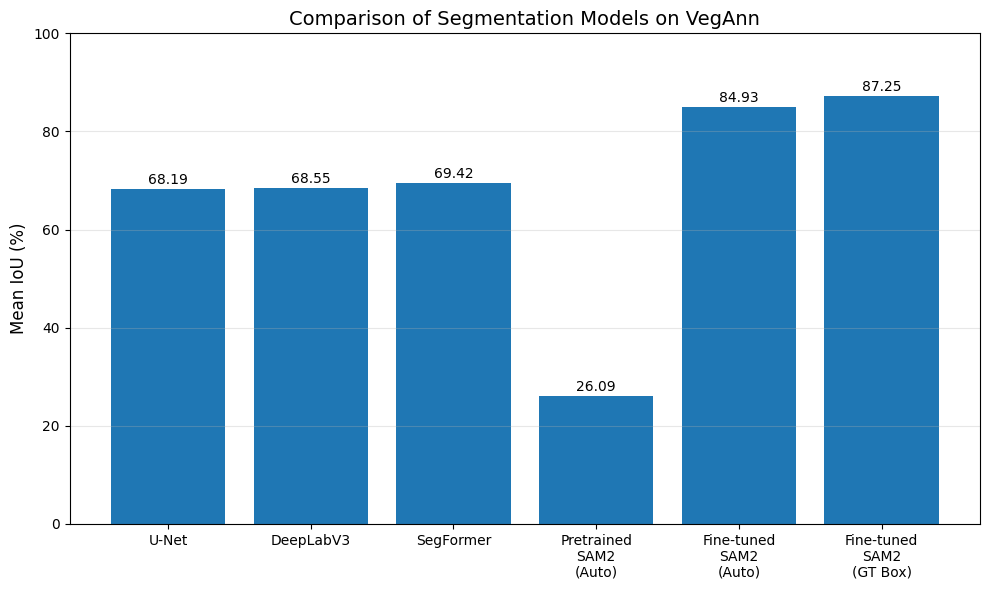

In [49]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "U-Net",
    "DeepLabV3",
    "SegFormer",
    "Pretrained\nSAM2\n(Auto)",
    "Fine-tuned\nSAM2\n(Auto)",
    "Fine-tuned\nSAM2\n(GT Box)"
]

mean_iou = [
    68.19,
    68.55,
    69.42,
    26.09,
    84.93,
    87.25
]

plt.figure(figsize=(10,6))

bars = plt.bar(models, mean_iou)

plt.ylabel("Mean IoU (%)", fontsize=12)
plt.title("Comparison of Segmentation Models on VegAnn", fontsize=14)
plt.ylim(0,100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x()+bar.get_width()/2,
        height+1,
        f"{height:.2f}",
        ha='center',
        fontsize=10
    )

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

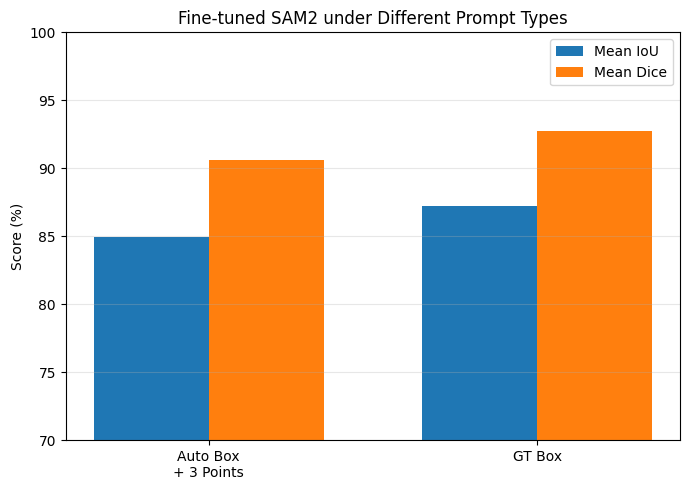

In [50]:
import matplotlib.pyplot as plt

prompts = [
    "Auto Box\n+ 3 Points",
    "GT Box"
]

iou = [
    84.93,
    87.25
]

dice = [
    90.64,
    92.75
]

x = np.arange(len(prompts))
width = 0.35

plt.figure(figsize=(7,5))

plt.bar(x-width/2, iou, width, label="Mean IoU")
plt.bar(x+width/2, dice, width, label="Mean Dice")

plt.xticks(x, prompts)

plt.ylim(70,100)

plt.ylabel("Score (%)")
plt.title("Fine-tuned SAM2 under Different Prompt Types")

plt.legend()

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
import pandas as pd

results = pd.DataFrame({
    "Model":[
        "U-Net",
        "DeepLabV3",
        "SegFormer",
        "Pretrained SAM2",
        "Fine-tuned SAM2",
        "Fine-tuned SAM2"
    ],

    "Prompt":[
        "None",
        "None",
        "None",
        "Auto Box + 3 Points",
        "Auto Box + 3 Points",
        "GT Box"
    ],

    "Mean IoU":[
        68.19,
        68.55,
        69.42,
        26.09,
        84.93,
        87.25
    ],

    "Mean Dice":[
        76.28,
        76.66,
        77.19,
        31.95,
        90.64,
        92.75
    ],

    "Global IoU":[
        82.49,
        84.51,
        85.74,
        None,
        88.89,
        90.60
    ],

    "Global Dice":[
        90.41,
        91.60,
        92.32,
        None,
        94.12,
        95.07
    ]
})

results

,Model,Prompt,Mean IoU,Mean Dice,Global IoU,Global Dice
0,U-Net,None,68.19,76.28,82.49,90.41
1,DeepLabV3,None,68.55,76.66,84.51,91.60
2,SegFormer,None,69.42,77.19,85.74,92.32
3,Pretrained SAM2,Auto Box + 3 Points,26.09,31.95,NaN,NaN
4,Fine-tuned SAM2,Auto Box + 3 Points,84.93,90.64,88.89,94.12
5,Fine-tuned SAM2,GT Box,87.25,92.75,90.60,95.07
